# TripGenie — India Tourism Data Exploration

## 1. Project introduction and EDA objectives
TripGenie is a personalized travel recommendation project inspired by Safarnaama. This notebook examines the supplied destination catalogue before any recommendation models are built. It does not reproduce or evaluate the research project.

**Objectives:** understand the schema and coverage; audit completeness and destination identity; explore interests, popularity, cost, access, and duration; and identify candidate features for future TF-IDF, cosine similarity, and hybrid recommendations.

**Scope:** findings describe this catalogue, not all Indian destinations or measured traveler demand. Ratings and prices are supplied metadata with no documented scoring methodology or currency unit in the JSON. No external facts or live prices are inferred.

## 2. Environment and reproducible data loading
Run cells from top to bottom using Python 3. Install `pandas`, `numpy`, `matplotlib`, `seaborn`, and `ipykernel` in your notebook environment. Execution and validation additionally use `nbformat` and `nbclient`. The path resolver supports execution from the repository root or its subdirectories.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="colorblind", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 85)

def observe(text):
    display(Markdown("**Observations.** " + text))

def find_dataset():
    for parent in (Path.cwd(), *Path.cwd().parents):
        candidate = parent / "data" / "india_tourism_dataset.json"
        if candidate.is_file():
            return candidate
    raise FileNotFoundError("Run this notebook from within the TripGenie repository.")

DATA_PATH = find_dataset()
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
with DATA_PATH.open(encoding="utf-8") as handle:
    records = json.load(handle)
if not isinstance(records, list) or not all(isinstance(row, dict) for row in records):
    raise ValueError("Expected a JSON array of destination objects.")
raw_df = pd.DataFrame(records)
# Flatten fixed-schema dictionaries, but retain variable-key audience explanations.
fixed_records = [{k: v for k, v in row.items() if k != "ideal_for_why"} for row in records]
df = pd.json_normalize(fixed_records, sep=".")
df["ideal_for_why"] = raw_df["ideal_for_why"]
print(f"Loaded {len(records):,} records from data/{DATA_PATH.name}")
print(f"Source SHA-256: {source_hash}")
display(pd.Series({"Python": platform.python_version(), "pandas": pd.__version__,
                   "NumPy": np.__version__, "Matplotlib": matplotlib.__version__,
                   "Seaborn": sns.__version__}, name="Execution versions").to_frame())

Loaded 100 records from data/india_tourism_dataset.json
Source SHA-256: 6bd466a668ccc80b3b21f37677a400b206deab043764dfa0d9057b8376b12051


,Execution versions
Python,3.12.7
pandas,3.0.6
NumPy,2.5.4
Matplotlib,3.11.2
Seaborn,0.13.2


## 3. Dataset structure and initial inspection
Each record represents a catalogue entry with a destination name and ID, geography, interest tags, transport access, three cost tiers, seasonal advice, durations, and descriptive text. Some destinations have multiple entries. `state` includes union territories and composite location labels; `region` includes an island and multi-state category.

`pd.json_normalize` expands fixed dictionaries into dotted columns. Lists remain lists: interest tags need explosion, while two-element cost ranges need explicit endpoints. `ideal_for_why` stays a dictionary because its audience keys vary between records. Temperature descriptions remain strings rather than being forced into unreliable numeric values.

In [2]:
print(f"Raw dimensions: {raw_df.shape[0]} rows × {raw_df.shape[1]} columns")
print(f"Analysis dimensions: {df.shape[0]} rows × {df.shape[1]} columns")
schema = pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values,
                       "non_null": df.notna().sum().values})
with pd.option_context("display.max_rows", None):
    display(schema)
display(df[["id", "destination_name", "state", "region", "trip_types",
            "budget_category.total_daily_range", "ideal_days"]].head())
display(raw_df.iloc[[0]][["coordinates", "nearest_airport", "budget_category", "ideal_for_why"]].T)
observe(f"There are {df['destination_name'].nunique()} distinct destination names across {len(df)} entries. "
        "Nested budget ranges and interest lists require different transformations; object dtype alone does not distinguish them.")

Raw dimensions: 100 rows × 54 columns
Analysis dimensions: 100 rows × 72 columns


,column,dtype,non_null
0,id,int64,100
1,state,str,100
2,district,str,100
3,region,str,100
4,altitude_m,int64,100
5,popularity_score,int64,100
6,accessibility,str,100
7,road_connectivity,str,100
8,trip_types,object,100
9,primary_attractions,object,100


,id,destination_name,state,region,trip_types,budget_category.total_daily_range,ideal_days
0,1,Goa,Goa,West India,"[Beach, Cultural, Food, Nightlife, Wellness, Photography]","[1400, 2800]",5.0
1,2,Ladakh (Leh),Ladakh,North India,"[Adventure, Nature, Cultural, Religious, Photography, Trekking]","[1500, 3400]",7.0
2,3,Jaipur,Rajasthan,North India,"[Heritage, Cultural, Photography, Shopping, Food]","[1300, 2600]",3.0
3,4,Varanasi (Kashi),Uttar Pradesh,North India,"[Religious, Spiritual, Cultural, Photography]","[1200, 2400]",3.0
4,5,Agra,Uttar Pradesh,North India,"[Heritage, Photography, Short_break]","[1400, 2800]",2.0


,0
coordinates,"{'latitude': 15.3, 'longitude': 73.8}"
nearest_airport,"{'name': 'Dabolim Airport', 'distance_km': 22}"
budget_category,"{'accommodation_range': [800, 1500], 'food_range': [300, 600], 'activities_range'..."
ideal_for_why,"{'Couple': 'Romantic sunsets, beach stays, quiet South Goa beaches', 'Friends': '..."


**Observations.** There are 93 distinct destination names across 100 entries. Nested budget ranges and interest lists require different transformations; object dtype alone does not distinguish them.

## 4. Data quality: missingness and duplicate identity
Check both pandas nulls and missing-like values inside nested lists/dictionaries. Explicit `data_not_available`, blank strings, and empty containers are reported separately from nulls. Phrases such as “Not required” are meaningful values and are retained. A missing railway distance is not interpreted as zero distance.

Duplicate names are candidate identity issues, not proof of redundant records. No automatic deduplication is applied. Case and whitespace normalization is used only for an additional duplicate audit.

In [3]:
missing = df.isna().sum().rename("null_count").to_frame()
missing["null_percent"] = missing.null_count / len(df) * 100
display(missing.query("null_count > 0"))

issues = []
def audit_nested(value, path, record_id):
    if value is None:
        issues.append((record_id, path, "null"))
    elif isinstance(value, str) and (not value.strip() or value.strip().casefold() == "data_not_available"):
        issues.append((record_id, path, "blank/sentinel"))
    elif isinstance(value, (dict, list)):
        if not value:
            issues.append((record_id, path, "empty container"))
        items = value.items() if isinstance(value, dict) else enumerate(value)
        for key, child in items:
            audit_nested(child, f"{path}.{key}" if path else str(key), record_id)
for row in records:
    audit_nested(row, "", row.get("id"))
issue_df = pd.DataFrame(issues, columns=["id", "field_path", "issue"])
display(issue_df)
name_key = df.destination_name.str.strip().str.casefold()
place_key = pd.DataFrame({"name": name_key, "state": df.state.str.strip().str.casefold()})
duplicate_summary = pd.Series({
    "Duplicate ID rows beyond first": int(df.id.duplicated().sum()),
    "Duplicate exact-name rows beyond first": int(df.destination_name.duplicated().sum()),
    "Duplicate normalized-name rows beyond first": int(name_key.duplicated().sum()),
    "Duplicate normalized name + state rows beyond first": int(place_key.duplicated().sum()),
    "Identical full records beyond first": int(pd.Series([json.dumps(r, sort_keys=True) for r in records]).duplicated().sum())
}, name="Count")
display(duplicate_summary.to_frame())
display(df.loc[name_key.duplicated(keep=False),
               ["id", "destination_name", "state", "region", "popularity_score", "ideal_days"]].sort_values("destination_name"))
observe(f"IDs have {df.id.duplicated().sum()} duplicates; exact destination names have "
        f"{df.destination_name.duplicated().sum()} repeated rows beyond the first. "
        f"The nested audit found {len(issue_df)} missing-like leaf/container values. "
        "Review repeated destinations before splitting or evaluating recommendations, and investigate unavailable transport distances rather than imputing zero.")

,null_count,null_percent
nearest_railway_station.distance_km,8,8.0


,id,field_path,issue
0,2,average_temperature.monsoon,blank/sentinel
1,31,nearest_railway_station.distance_km,null
2,32,nearest_railway_station.distance_km,null
3,49,nearest_railway_station.distance_km,null
4,50,nearest_railway_station.distance_km,null
5,61,nearest_railway_station.distance_km,null
6,62,nearest_railway_station.distance_km,null
7,63,nearest_railway_station.distance_km,null
8,88,nearest_railway_station.distance_km,null


,Count
Duplicate ID rows beyond first,0
Duplicate exact-name rows beyond first,7
Duplicate normalized-name rows beyond first,7
Duplicate normalized name + state rows beyond first,7
Identical full records beyond first,0


,id,destination_name,state,region,popularity_score,ideal_days
7,8,Coorg (Kodagu),Karnataka,South India,7,3.0
52,53,Coorg (Kodagu),Karnataka,South India,8,3.0
24,25,Gokarna,Karnataka,South India,6,3.0
70,71,Gokarna,Karnataka,South India,8,3.0
30,31,Havelock Island (Swaraj Dweep),Andaman and Nicobar Islands,Island Territory,9,3.0
60,61,Havelock Island (Swaraj Dweep),Andaman and Nicobar Islands,Island Territory,9,3.0
31,32,Neil Island (Shaheed Dweep),Andaman and Nicobar Islands,Island Territory,7,2.0
61,62,Neil Island (Shaheed Dweep),Andaman and Nicobar Islands,Island Territory,8,2.0
15,16,Spiti Valley,Himachal Pradesh,North India,6,7.0
73,74,Spiti Valley,Himachal Pradesh,North India,8,7.0


**Observations.** IDs have 0 duplicates; exact destination names have 7 repeated rows beyond the first. The nested audit found 9 missing-like leaf/container values. Review repeated destinations before splitting or evaluating recommendations, and investigate unavailable transport distances rather than imputing zero.

## 5. Geographic coverage: state/location and region
These charts count catalogue entries, including repeated destination names. The coverage table also shows distinct names within each state/location label. Composite labels are retained as supplied and are not counted as individual administrative states. The explicit analysis-only mapping merges `North East India` into `Northeast India`; the raw region distribution remains visible.

,entries,distinct_names
state,,
Karnataka,11,9
Uttarakhand,10,10
Himachal Pradesh,9,8
Tamil Nadu,6,6
Rajasthan,6,6
Meghalaya,6,6
Andaman and Nicobar Islands,5,3
Uttar Pradesh,4,3
Maharashtra,4,4


,raw_entries,harmonized_entries
Central India,6,6
East India,3,3
Island Territory,8,8
Multi-state,1,1
North East India,6,0
North India,31,31
Northeast India,8,14
South India,24,24
West India,13,13


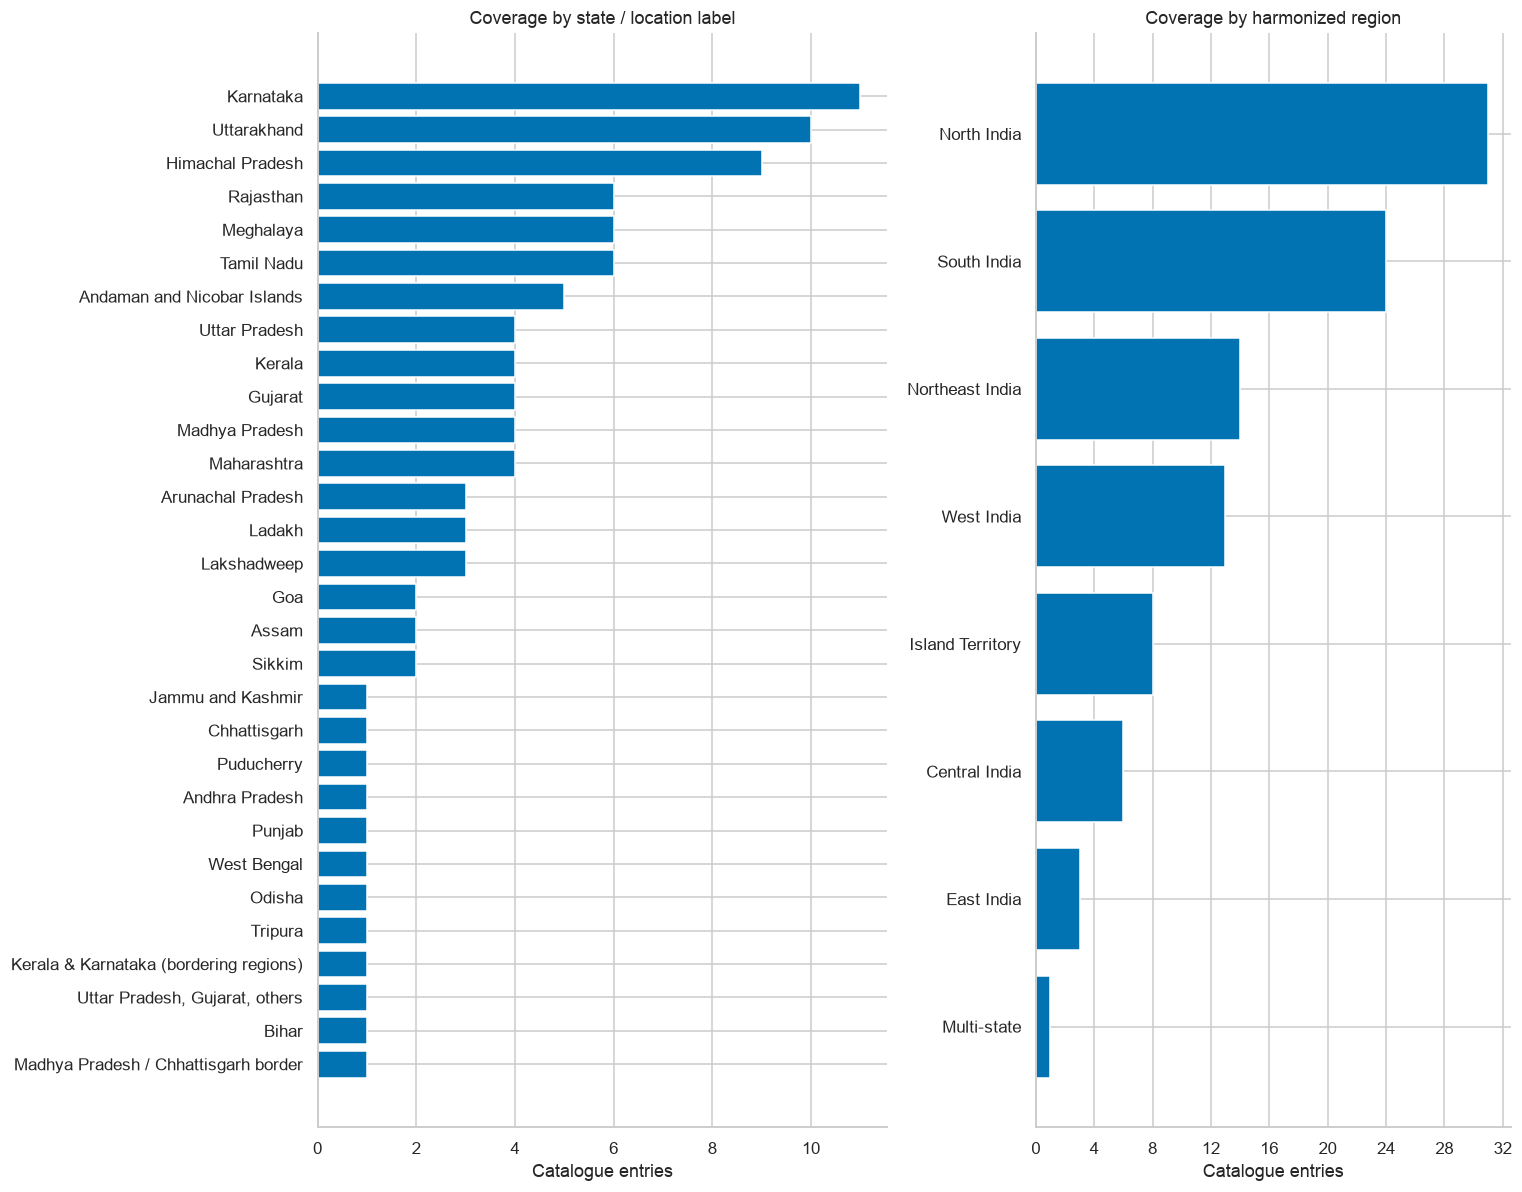

**Observations.** The catalogue covers 30 state/location labels. Karnataka has the most entries (11). Region harmonization changes 9 raw labels to 8 labels. Uneven catalogue coverage and duplicate entries can bias a future recommender's apparent geographic diversity.

In [4]:
def count_bar(counts, ax, title, xlabel="Catalogue entries"):
    ordered = counts.sort_values()
    ax.barh(ordered.index.astype(str), ordered.values, color=sns.color_palette("colorblind")[0])
    ax.set(title=title, xlabel=xlabel, ylabel="")
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))

region_mapping = {"North East India": "Northeast India"}
df["region_analysis"] = df.region.replace(region_mapping)
state_counts = df.state.value_counts()
state_coverage = pd.DataFrame({"entries": state_counts,
                              "distinct_names": df.groupby("state").destination_name.nunique()}).sort_values("entries", ascending=False)
display(state_coverage)
display(pd.DataFrame({"raw_entries": df.region.value_counts(),
                      "harmonized_entries": df.region_analysis.value_counts()}).fillna(0).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(14, 11), gridspec_kw={"width_ratios": [1.2, 1]})
count_bar(state_counts, axes[0], "Coverage by state / location label")
count_bar(df.region_analysis.value_counts(), axes[1], "Coverage by harmonized region")
fig.tight_layout(); plt.show()
observe(f"The catalogue covers {df.state.nunique()} state/location labels. "
        f"{state_counts.index[0]} has the most entries ({state_counts.iloc[0]}). "
        f"Region harmonization changes {df.region.nunique()} raw labels to {df.region_analysis.nunique()} labels. "
        "Uneven catalogue coverage and duplicate entries can bias a future recommender's apparent geographic diversity.")

## 6. Trip types and multi-label interests
Explode lists into one row per entry–tag pair and deduplicate within each entry. Percentages use the number of catalogue entries as the denominator; they need not sum to 100%. The chart shows the 20 most frequent tags, while the table includes every tag. Similar labels such as `Culture` and `Cultural` remain separate pending a reviewed vocabulary mapping.

,list_column,non_list_rows
0,trip_types,0
1,primary_attractions,0
2,activities_available,0
3,hidden_gems,0
4,best_seasons,0
5,avoid_seasons,0
6,ideal_for,0
7,accommodation_types,0
8,mobile_network,0
9,language_spoken,0


,entries,percent_of_entries
trip_types,,
Photography,34,34.0
Nature,21,21.0
Family,21,21.0
Offbeat,21,21.0
Spiritual,19,19.0
Heritage,18,18.0
Short_break,18,18.0
Beach,13,13.0
Hill_station,13,13.0


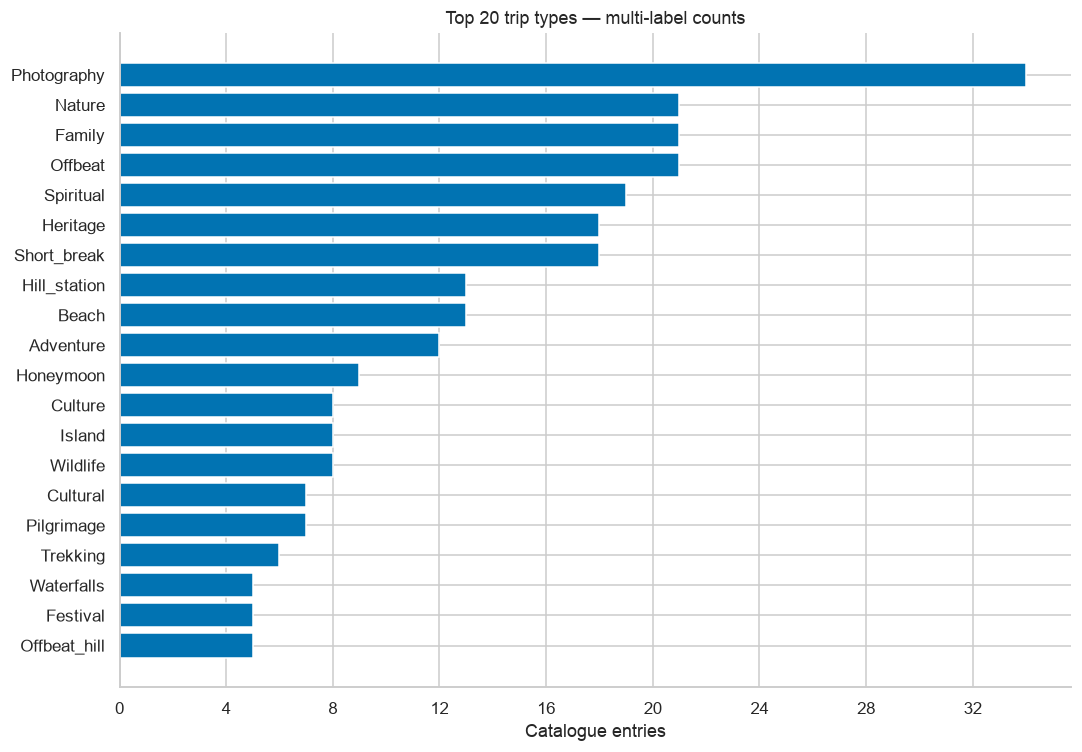

**Observations.** There are 103 distinct trip-type labels. The most frequent is Photography (34 entries; 34% of the catalogue). Entries have a median of 4 tags. The long tail and overlapping wording suggest a controlled tag vocabulary would help future matching.

In [5]:
list_columns = [c for c in df if df[c].map(lambda v: isinstance(v, list)).any()]
display(pd.DataFrame({"list_column": list_columns,
                      "non_list_rows": [int((~df[c].map(lambda v: isinstance(v, list))).sum()) for c in list_columns]}))
trip_long = df[["id", "trip_types"]].explode("trip_types").dropna(subset=["trip_types"]).drop_duplicates(["id", "trip_types"])
trip_counts = trip_long.trip_types.value_counts()
trip_summary = trip_counts.rename("entries").to_frame()
trip_summary["percent_of_entries"] = trip_counts / len(df) * 100
with pd.option_context("display.max_rows", None):
    display(trip_summary.round(1))
fig, ax = plt.subplots(figsize=(10, 7))
count_bar(trip_counts.head(20), ax, "Top 20 trip types — multi-label counts")
fig.tight_layout(); plt.show()
observe(f"There are {len(trip_counts)} distinct trip-type labels. The most frequent is "
        f"{trip_counts.index[0]} ({trip_counts.iloc[0]} entries; {trip_counts.iloc[0] / len(df):.0%} of the catalogue). "
        f"Entries have a median of {df.trip_types.map(len).median():g} tags. "
        "The long tail and overlapping wording suggest a controlled tag vocabulary would help future matching.")

## 7. Popularity scores
Popularity is treated as a supplied numeric feature, not as observed bookings, clicks, or a calibrated preference probability. Summaries by region include group sizes so small groups are visible.

,popularity_score
count,100.000000
mean,7.380000
std,1.440959
min,4.000000
25%,6.000000
50%,7.000000
75%,9.000000
max,10.000000


,count,mean,median,min,max
region_analysis,,,,,
Central India,6,6.67,6.5,5,8
East India,3,8.00,9.0,6,9
Island Territory,8,7.50,7.5,5,9
Multi-state,1,9.00,9.0,9,9
North India,31,7.90,8.0,5,10
Northeast India,14,6.71,7.0,5,8
South India,24,7.00,7.0,4,9
West India,13,7.54,8.0,5,9


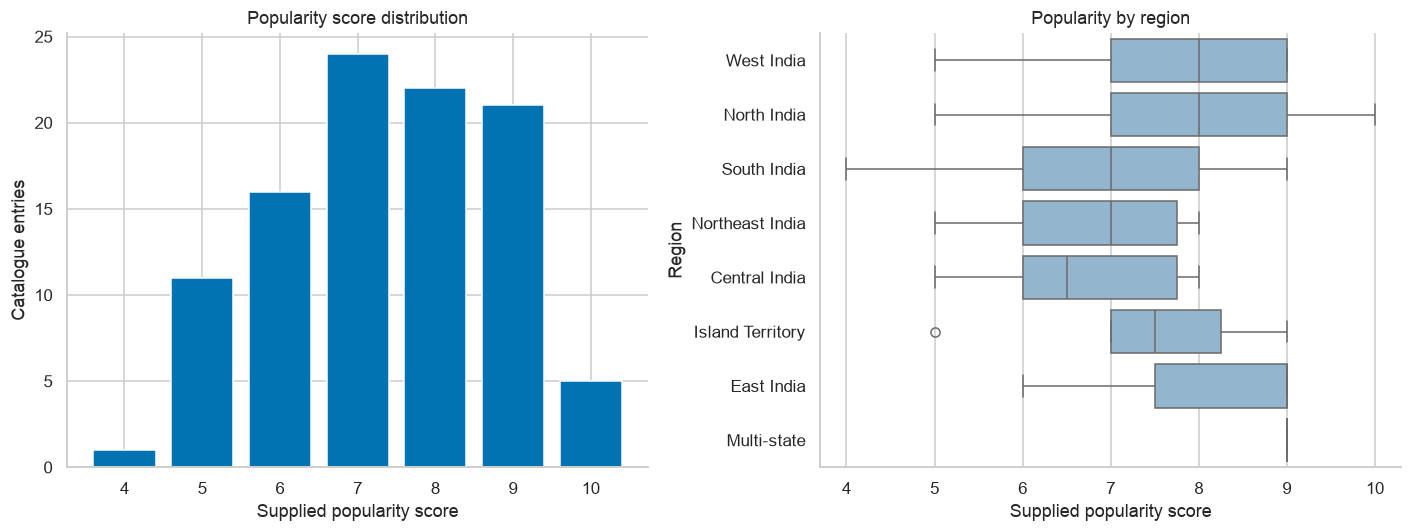

**Observations.** Scores range from 4 to 10, with mean 7.38 and median 7. A future popularity component should be evaluated for bias toward already prominent entries; these scores alone do not establish user satisfaction.

In [6]:
display(df.popularity_score.describe().to_frame())
display(df.groupby("region_analysis").popularity_score.agg(["count", "mean", "median", "min", "max"]).round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
score_counts = df.popularity_score.value_counts().sort_index()
axes[0].bar(score_counts.index, score_counts.values)
axes[0].set(title="Popularity score distribution", xlabel="Supplied popularity score", ylabel="Catalogue entries")
sns.boxplot(data=df, x="popularity_score", y="region_analysis", ax=axes[1], color="#8ab6d6")
axes[1].set(title="Popularity by region", xlabel="Supplied popularity score", ylabel="Region")
fig.tight_layout(); plt.show()
observe(f"Scores range from {df.popularity_score.min():g} to {df.popularity_score.max():g}, "
        f"with mean {df.popularity_score.mean():.2f} and median {df.popularity_score.median():g}. "
        "A future popularity component should be evaluated for bias toward already prominent entries; these scores alone do not establish user satisfaction.")

## 8. Budget ranges across travel tiers
Each tier contains accommodation, food, activities, local transport, and total daily ranges. Validate all endpoints before creating derived low/high/midpoint columns. The midpoint is an arithmetic summary of a range, not an observed mean expense. Currency and per-person assumptions are undocumented, so plots use **dataset currency units per day**.

Compare supplied totals with component sums as an internal consistency check. A discrepancy is reported for review, without replacing the supplied total.

,field,invalid_rows
0,budget_category.accommodation_range,0
1,budget_category.food_range,0
2,budget_category.activities_range,0
3,budget_category.local_transport_range,0
4,budget_category.total_daily_range,0
5,mid_range_category.accommodation_range,0
6,mid_range_category.food_range,0
7,mid_range_category.activities_range,0
8,mid_range_category.local_transport_range,0
9,mid_range_category.total_daily_range,0


low                 high                 midpoint           \
            min  median    max   min   median    max      min   median   
tier                                                                     
Budget      700  1550.0   6600  1600   3375.0  12000   1150.0   2412.5   
Mid-range  1100  3050.0  11000  2400   6400.0  20500   1750.0   4725.0   
Luxury     1600  6400.0  19000  3100  17750.0  42500   2350.0  12150.0   

                   range_width                  
               max         min   median    max  
tier                                            
Budget      9300.0         900   1900.0   6100  
Mid-range  15750.0        1300   3400.0   9500  
Luxury     30750.0        1500  11050.0  23500

,id,destination_name,tier,low,high,midpoint,range_width,low_matches_components,high_matches_components
167,68,Kaziranga National Park & Assam Tea Belt,Mid-range,7100,13500,10300.0,6400,True,False
171,72,Almora & Kasar Devi Belt,Mid-range,2650,6050,4350.0,3400,True,False
193,94,Rameswaram & Pamban Coast (Sacred Water Walk),Mid-range,2400,5450,3925.0,3050,True,False
203,4,Varanasi (Kashi),Luxury,6900,23800,15350.0,16900,True,False
204,5,Agra,Luxury,7000,24800,15900.0,17800,True,False
240,41,Kanatal,Luxury,5200,20100,12650.0,14900,True,False
242,43,Munsiyari,Luxury,5200,19900,12550.0,14700,True,False
243,44,Chakrata,Luxury,4700,15800,10250.0,11100,True,False
257,58,Amboli Ghat,Luxury,5400,16200,10800.0,10800,True,False
258,59,Agumbe & Western Ghats Rainforest Belt,Luxury,6100,16700,11400.0,10600,True,False


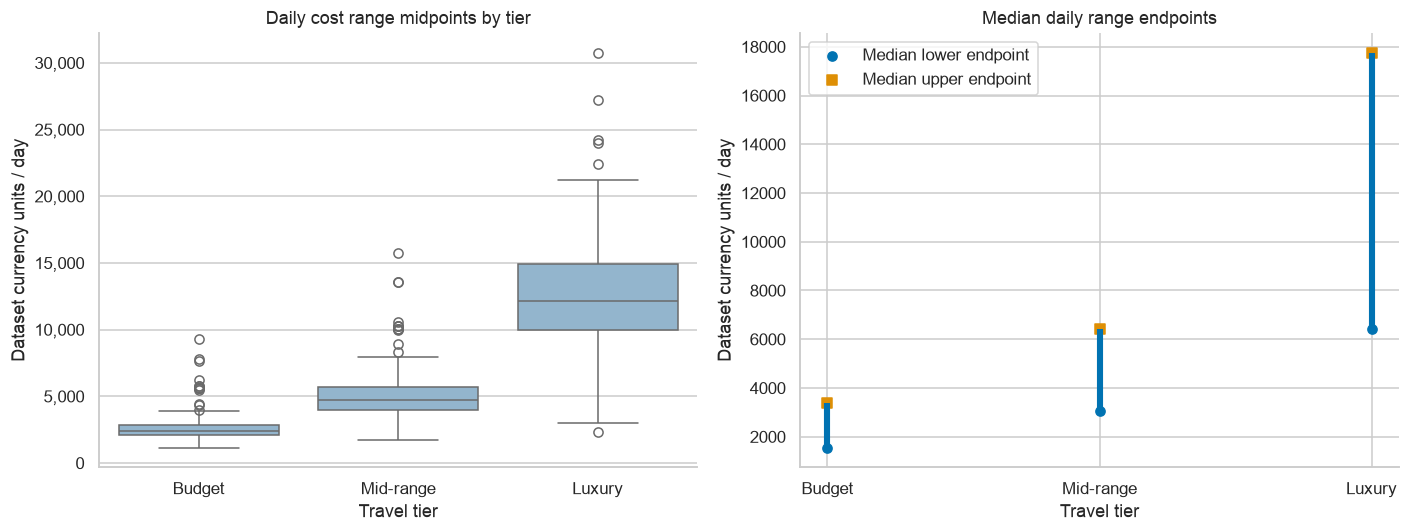

**Observations.** Median daily range midpoints: Budget: 2,412.5; Mid-range: 4,725.0; Luxury: 12,150.0. There are 0 invalid range cells and 14 entry–tier pairs whose totals do not match both component sums. Use endpoints for budget compatibility checks; a midpoint alone can hide wide uncertainty.

In [7]:
tiers = {"Budget": "budget_category", "Mid-range": "mid_range_category", "Luxury": "luxury_category"}
components = ["accommodation", "food", "activities", "local_transport"]
budget_checks = []
budget_frames = []
for label, prefix in tiers.items():
    for component in [*components, "total_daily"]:
        column = f"{prefix}.{component}_range"
        valid = df[column].map(lambda v: isinstance(v, list) and len(v) == 2
                               and all(isinstance(x, (int, float)) and not isinstance(x, bool)
                                       and np.isfinite(x) for x in v)
                               and 0 <= v[0] <= v[1])
        budget_checks.append({"field": column, "invalid_rows": int((~valid).sum())})
        for endpoint, position in [("low", 0), ("high", 1)]:
            df[f"{prefix}.{component}_{endpoint}"] = df[column].map(
                lambda v: v[position] if isinstance(v, list) and len(v) == 2 else np.nan).where(valid)
    low = df[f"{prefix}.total_daily_low"]
    high = df[f"{prefix}.total_daily_high"]
    frame = df[["id", "destination_name"]].copy()
    frame["tier"] = label; frame["low"] = low; frame["high"] = high
    frame["midpoint"] = (low + high) / 2
    frame["range_width"] = high - low
    for endpoint in ["low", "high"]:
        component_sum = df[[f"{prefix}.{c}_{endpoint}" for c in components]].sum(axis=1, min_count=4)
        frame[f"{endpoint}_matches_components"] = np.isclose(frame[endpoint], component_sum, equal_nan=False)
    budget_frames.append(frame)
budget_long = pd.concat(budget_frames, ignore_index=True)
display(pd.DataFrame(budget_checks))
display(budget_long.groupby("tier", sort=False)[["low", "high", "midpoint", "range_width"]].agg(["min", "median", "max"]).round(1))
budget_mismatches = budget_long.loc[~(budget_long.low_matches_components & budget_long.high_matches_components)]
display(budget_mismatches)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=budget_long, x="tier", y="midpoint", order=list(tiers), ax=axes[0], color="#8ab6d6")
axes[0].set(title="Daily cost range midpoints by tier", xlabel="Travel tier", ylabel="Dataset currency units / day")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
medians = budget_long.groupby("tier", sort=False)[["low", "high"]].median().reindex(tiers)
x = np.arange(len(medians))
axes[1].vlines(x, medians.low, medians.high, color="#0072b2", linewidth=4)
axes[1].scatter(x, medians.low, label="Median lower endpoint")
axes[1].scatter(x, medians.high, marker="s", label="Median upper endpoint")
axes[1].set(xticks=x, xticklabels=medians.index, title="Median daily range endpoints", xlabel="Travel tier", ylabel="Dataset currency units / day")
axes[1].legend(); fig.tight_layout(); plt.show()
observe("Median daily range midpoints: " + "; ".join(
    f"{tier}: {value:,.1f}" for tier, value in budget_long.groupby("tier", sort=False).midpoint.median().items())
    + f". There are {sum(r['invalid_rows'] for r in budget_checks)} invalid range cells and "
    f"{len(budget_mismatches)} entry–tier pairs whose totals do not match both component sums. "
    "Use endpoints for budget compatibility checks; a midpoint alone can hide wide uncertainty.")

## 9. Accessibility and transport proximity
Accessibility is categorical and transport distances are numeric. Category counts and distance distributions complement each other; transport proximity does not capture service frequency, seasonal closures, or mobility needs. A built-in symmetric-logarithmic scale is linear from 0 to 1 km and logarithmic above 1 km, preserving zero distances while making long tails readable.

,entries
accessibility,
Moderate,67
Easy,20
Difficult,13


,count,mean,std,min,25%,50%,75%,max
nearest_airport.distance_km,100.0,97.3,77.3,0.0,33.8,81.5,140.0,320.0
nearest_railway_station.distance_km,92.0,86.3,115.6,0.0,5.0,42.5,100.0,570.0
nearest_major_city.distance_km,100.0,152.6,166.1,0.0,55.0,110.0,185.0,1300.0


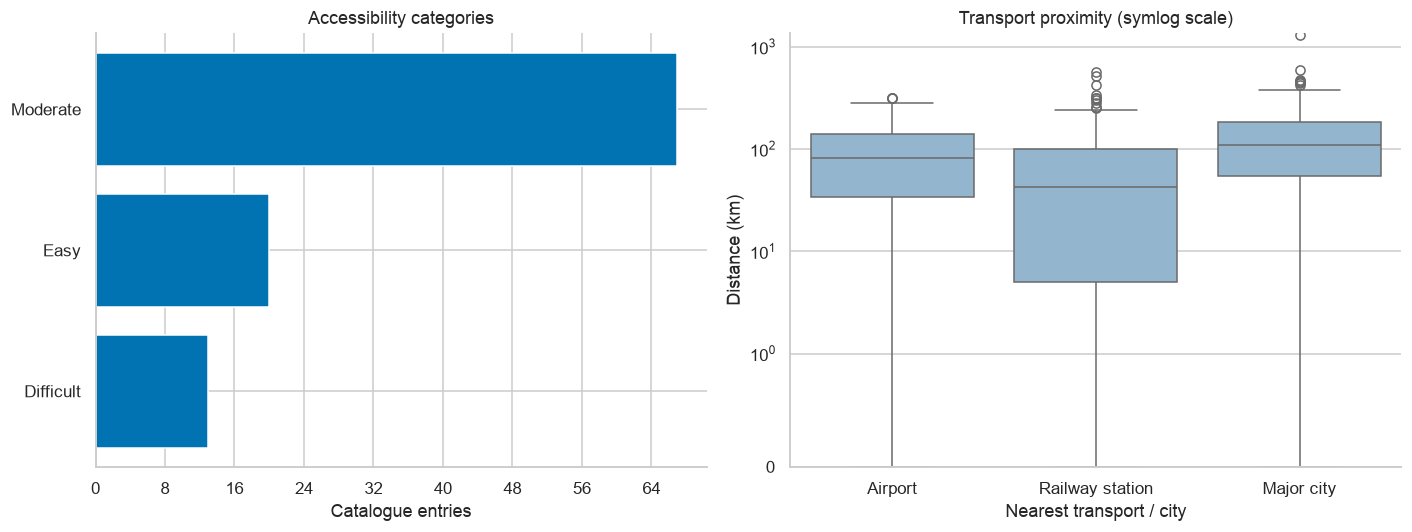

**Observations.** Moderate is the most frequent accessibility label (67 entries). Railway distance is missing for 8 entries. Keep missing-distance indicators and route descriptions available rather than treating category labels as a complete measure of ease of travel.

In [8]:
access_counts = df.accessibility.value_counts()
display(access_counts.rename("entries").to_frame())
distance_cols = ["nearest_airport.distance_km", "nearest_railway_station.distance_km", "nearest_major_city.distance_km"]
display(df[distance_cols].describe().T.round(1))
distance_long = df.melt(id_vars=["id", "accessibility"], value_vars=distance_cols,
                        var_name="transport", value_name="distance_km")
distance_long["transport"] = distance_long.transport.map(dict(zip(distance_cols, ["Airport", "Railway station", "Major city"])))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
count_bar(access_counts, axes[0], "Accessibility categories")
sns.boxplot(data=distance_long, x="transport", y="distance_km", ax=axes[1], color="#8ab6d6")
axes[1].set_yscale("symlog", linthresh=1)
axes[1].set_ylim(bottom=0)
axes[1].set(title="Transport proximity (symlog scale)", xlabel="Nearest transport / city", ylabel="Distance (km)")
fig.tight_layout(); plt.show()
observe(f"{access_counts.index[0]} is the most frequent accessibility label ({access_counts.iloc[0]} entries). "
        f"Railway distance is missing for {df[distance_cols[1]].isna().sum()} entries. "
        "Keep missing-distance indicators and route descriptions available rather than treating category labels as a complete measure of ease of travel.")

## 10. Recommended trip durations
Minimum, ideal, and maximum durations are expressed in days. Fractional-day recommendations are preserved. Ordering violations are displayed, and ideal duration is compared across trip types with at least five entries; categories overlap, so those comparisons are descriptive.

,minimum_days,ideal_days,maximum_days
count,100.00,100.00,100.00
mean,1.95,2.84,4.65
std,0.97,1.28,2.24
min,0.50,0.50,1.00
25%,1.00,2.00,3.00
50%,2.00,3.00,4.00
75%,2.00,3.00,5.00
max,6.00,7.00,14.00


,id,destination_name,minimum_days,ideal_days,maximum_days


,count,median
trip_types,,
Adventure,12,4.0
Trekking,6,3.5
Beach,13,3.0
Spiritual,19,3.0
Slow_travel,5,3.0
Short_break,18,3.0
Pilgrimage,7,3.0
Photography,34,3.0
Offbeat_hill,5,3.0


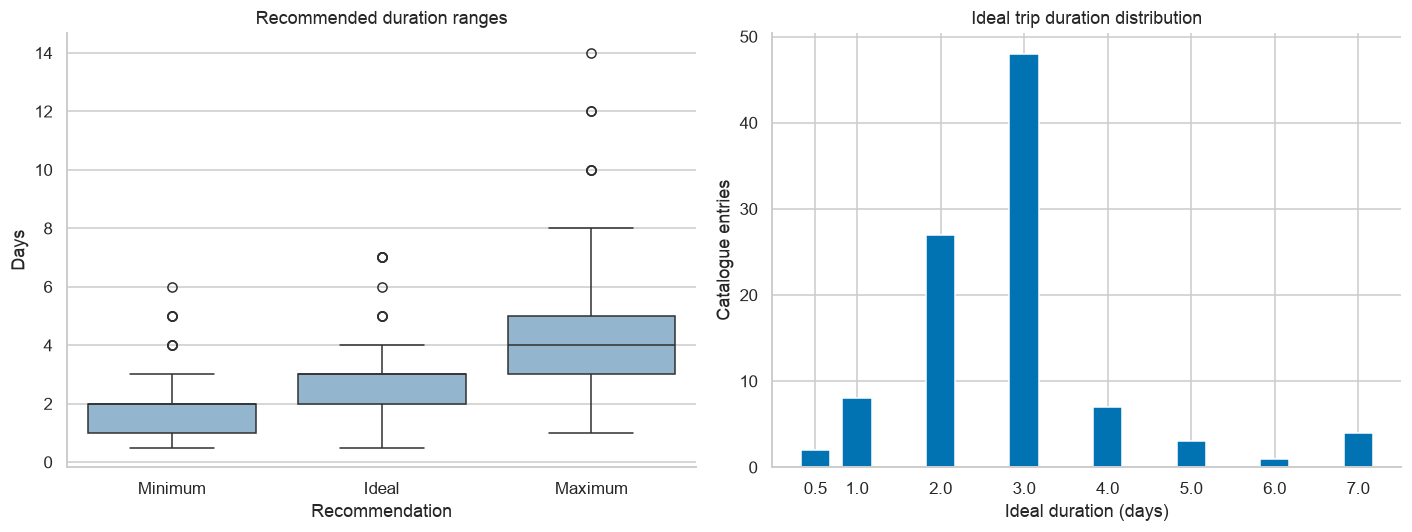

**Observations.** Ideal durations range from 0.5 to 7 days, with median 3 days. 0 entries violate positive, ordered durations. Duration endpoints can support itinerary-length filters; retain fractional days for short visits.

In [9]:
duration_cols = ["minimum_days", "ideal_days", "maximum_days"]
display(df[duration_cols].describe().round(2))
valid_duration = (df.minimum_days > 0) & (df.minimum_days <= df.ideal_days) & (df.ideal_days <= df.maximum_days)
display(df.loc[~valid_duration, ["id", "destination_name", *duration_cols]])
duration_tags = trip_long.merge(df[["id", "ideal_days"]], on="id", validate="many_to_one")
tag_duration = duration_tags.groupby("trip_types").ideal_days.agg(["count", "median"]).query("count >= 5").sort_values("median", ascending=False)
display(tag_duration)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df[duration_cols].rename(columns={"minimum_days": "Minimum", "ideal_days": "Ideal", "maximum_days": "Maximum"}), ax=axes[0], color="#8ab6d6")
axes[0].set(title="Recommended duration ranges", xlabel="Recommendation", ylabel="Days")
ideal_counts = df.ideal_days.value_counts().sort_index()
axes[1].bar(ideal_counts.index, ideal_counts.values, width=0.35)
axes[1].set_xticks(ideal_counts.index)
axes[1].set(title="Ideal trip duration distribution", xlabel="Ideal duration (days)", ylabel="Catalogue entries")
fig.tight_layout(); plt.show()
observe(f"Ideal durations range from {df.ideal_days.min():g} to {df.ideal_days.max():g} days, "
        f"with median {df.ideal_days.median():g} days. {int((~valid_duration).sum())} entries violate positive, ordered durations. "
        "Duration endpoints can support itinerary-length filters; retain fractional days for short visits.")

## 11. Candidate feature readiness and exploratory relationships
Inspect text availability and a small set of numeric relationships without fitting vectorizers or models. Spearman correlation describes monotonic associations within this catalogue; it is not causal evidence or validation of a recommendation strategy.

,field,nonempty_entries,median_words
0,destination_name,100,3.0
1,trip_types,100,4.0
2,primary_attractions,100,18.0
3,activities_available,100,15.0
4,unique_experiences,100,16.0
5,hidden_gems,100,14.0
6,local_culture,100,9.0
7,food_scene,100,11.0
8,user_reviews_summary,100,15.0


,entries
ideal_for,
Families,34
Couples,25
Photographers,20
Nature_lovers,10
Backpackers,9
Culture_seekers,7
Spiritual_seekers,5
Honeymooners,5
Adventure_seekers,4


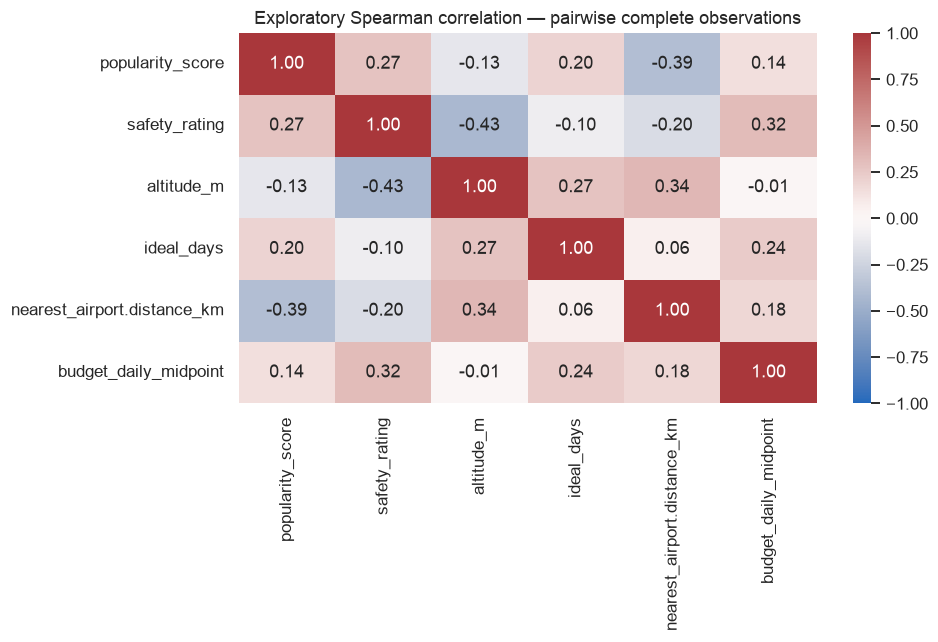

,popularity_score,safety_rating,altitude_m,ideal_days,nearest_airport.distance_km,budget_daily_midpoint
Pairwise sample counts,,,,,,
popularity_score,100,100,100,100,100,100
safety_rating,100,100,100,100,100,100
altitude_m,100,100,100,100,100,100
ideal_days,100,100,100,100,100,100
nearest_airport.distance_km,100,100,100,100,100,100
budget_daily_midpoint,100,100,100,100,100,100


**Observations.** The 9 inspected text/list fields are summarized above for coverage and length. Audience tags contain spelling and granularity variants (for example, Couple and Couples); normalize reviewed aliases before encoding. Long descriptions should not automatically outweigh short interest lists, and correlations do not establish which features improve personalization.

In [10]:
text_fields = ["destination_name", "trip_types", "primary_attractions", "activities_available",
               "unique_experiences", "hidden_gems", "local_culture", "food_scene", "user_reviews_summary"]
def text_parts(value):
    if isinstance(value, dict):
        return " ".join(text_parts(v) for v in value.values())
    if isinstance(value, list):
        return " ".join(text_parts(v) for v in value)
    if value is None or (not isinstance(value, (list, dict)) and pd.isna(value)):
        return ""
    text = str(value).strip()
    return "" if text.casefold() == "data_not_available" else text

text_readiness = pd.DataFrame({"field": text_fields,
    "nonempty_entries": [int(df[c].map(text_parts).str.len().gt(0).sum()) for c in text_fields],
    "median_words": [df[c].map(text_parts).str.split().map(len).median() for c in text_fields]})
display(text_readiness)
audience_counts = df.ideal_for.explode().value_counts()
display(audience_counts.head(15).rename("entries").to_frame())
numeric_features = df[["popularity_score", "safety_rating", "altitude_m", "ideal_days", "nearest_airport.distance_km"]].copy()
numeric_features["budget_daily_midpoint"] = (df["budget_category.total_daily_low"] + df["budget_category.total_daily_high"]) / 2
corr = numeric_features.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="vlag", ax=ax)
ax.set_title("Exploratory Spearman correlation — pairwise complete observations")
fig.tight_layout(); plt.show()
display(numeric_features.notna().astype(int).T.dot(numeric_features.notna().astype(int)).rename_axis("Pairwise sample counts"))
observe(f"The {len(text_fields)} inspected text/list fields are summarized above for coverage and length. "
        "Audience tags contain spelling and granularity variants (for example, Couple and Couples); normalize reviewed aliases before encoding. "
        "Long descriptions should not automatically outweigh short interest lists, and correlations do not establish which features improve personalization.")

## 12. Key findings and future recommendation features
The following summary is calculated from executed analysis cells, so its numbers remain tied to the source file.

In [11]:
observe(
    f"The catalogue contains {len(df)} entries and {df.destination_name.nunique()} distinct exact destination names, "
    f"covering {df.state.nunique()} state/location labels. {state_counts.index[0]} has the most entries "
    f"({state_counts.iloc[0]}), and {trip_counts.index[0]} is the most common trip tag ({trip_counts.iloc[0]} entries). "
    f"Popularity has median {df.popularity_score.median():g}; ideal trip length has median {df.ideal_days.median():g} days. "
    f"There are {df.id.duplicated().sum()} repeated IDs and {df.destination_name.duplicated().sum()} repeated name rows beyond the first. "
    "Identity review, vocabulary harmonization, missing-value handling, and verification of cost units should precede model development.")

**Observations.** The catalogue contains 100 entries and 93 distinct exact destination names, covering 30 state/location labels. Karnataka has the most entries (11), and Photography is the most common trip tag (34 entries). Popularity has median 7; ideal trip length has median 3 days. There are 0 repeated IDs and 7 repeated name rows beyond the first. Identity review, vocabulary harmonization, missing-value handling, and verification of cost units should precede model development.

| Future use | Candidate fields | Preparation and interpretation |
|---|---|---|
| TF-IDF content representation | `trip_types`, `primary_attractions`, `activities_available`, `unique_experiences`, `hidden_gems`, `local_culture`, `food_scene` | Join list items as readable text; remove missing sentinels; normalize reviewed aliases; consider field weighting. Preserve a mapping back to destination IDs. |
| Cosine similarity | Future TF-IDF vectors and separately encoded multi-label interests | Normalize vectors; inspect generic shared terms and near-duplicate destination entries; cosine similarity is a matching method, not a dataset feature. |
| Hybrid constraints and ranking | Daily cost endpoints, `minimum_days`, `ideal_days`, `maximum_days`, state, harmonized region, accessibility, transport distances, `best_seasons`, `ideal_for`, `permits_required` | Separate hard user constraints from soft preferences. Scale numeric features and encode categories; keep explicit missing indicators. |
| Optional ranking signals | `popularity_score`, `safety_rating` | Scoring definitions are undocumented; validate weights and audit bias rather than treating metadata ratings as ground truth. |
| Explanations | Attractions, activities, audience explanations, seasonal and special considerations | Ground explanations in catalogue fields; retain source context and refresh travel-sensitive details before product use. |
| Provenance and identity | `id`, `destination_name`, `last_updated`, `data_sources` | Keep for audit and reconciliation. Source tokens such as `web:185` are not independently resolvable citations. Exclude IDs and provenance tokens from semantic matching. |

**Limitations and next steps.** This is a small supplied catalogue with uneven coverage and repeated destinations. There are no user–item interactions or labeled relevance outcomes in the inspected schema, so a collaborative component or claims about recommendation accuracy are not yet supported. Reconcile destination identity before train/test splitting; overlapping destinations can leak into both sets. Review raw source provenance, vocabulary, seasonal terms, and price assumptions, then design a separate recommendation and evaluation notebook. No models are trained here.

## 13. Execution checks and source integrity
These checks confirm internal transformations and that the original dataset remains unchanged. They do not validate real-world prices, safety, or travel advice.

In [12]:
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_hash, "Source dataset changed."
assert len(df) == len(records), "Analysis must retain all catalogue entries."
assert len(trip_long) == sum(len(set(tags)) for tags in df.trip_types), "Trip-tag counts changed."
assert len(budget_long) == len(df) * len(tiers)
assert df.region_analysis.value_counts().sum() == len(df)
assert set(text_fields).issubset(df.columns)
print("Execution checks passed. The original JSON is unchanged; no recommendation models were created.")

Execution checks passed. The original JSON is unchanged; no recommendation models were created.
